<a href="https://colab.research.google.com/github/anushreemscs24-wq/AiLAB/blob/main/1WN24CS046_WEEK7_PARALLEL_CELLULAR_ALGORITHM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Intervention Location: (np.int64(0), np.int64(17))
Best Safety Fitness: 1.0
Final Healthy Cells: 86
Final Infected Cells: 343
Final Recovered Cells: 471


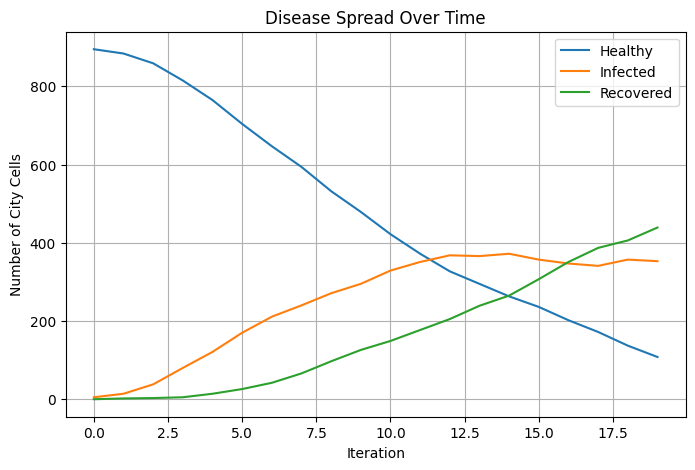

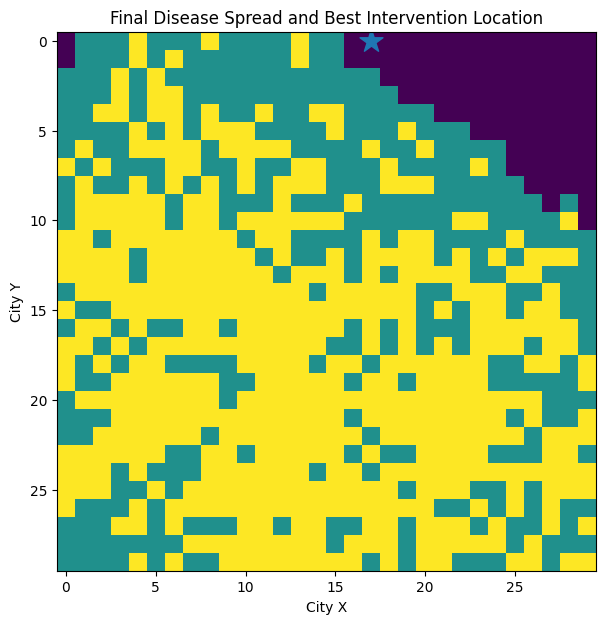

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the Problem
# 0 = Healthy
# 1 = Infected
# 2 = Recovered

size = 30
iterations = 20

# 2. Initialize Parameters
np.random.seed(10)

infection_rate = 0.25
recovery_rate = 0.10

# 3. Initialize Population
city = np.zeros((size, size))

# Initial infected cells
for i in range(5):
    x = np.random.randint(5, size - 5)
    y = np.random.randint(5, size - 5)
    city[x, y] = 1

infected_count = []
healthy_count = []
recovered_count = []

# 4. Evaluate Fitness
def calculate_fitness(city):
    fitness = np.zeros((size, size))

    for i in range(size):
        for j in range(size):
            if city[i, j] == 0:
                neighbors = city[
                    max(0, i-1):min(size, i+2),
                    max(0, j-1):min(size, j+2)
                ]

                infected_neighbors = np.sum(neighbors == 1)

                fitness[i, j] = 1 / (1 + infected_neighbors)

    return fitness


# 5. Update States using Neighboring Cells
def update_cells(city):

    new_city = city.copy()

    for i in range(size):
        for j in range(size):

            neighbors = city[
                max(0, i-1):min(size, i+2),
                max(0, j-1):min(size, j+2)
            ]

            infected_neighbors = np.sum(neighbors == 1)

            if city[i, j] == 0:

                if infected_neighbors > 0:
                    probability = infection_rate * infected_neighbors

                    if np.random.rand() < probability:
                        new_city[i, j] = 1

            elif city[i, j] == 1:

                if np.random.rand() < recovery_rate:
                    new_city[i, j] = 2

    return new_city


# 6. Iterate
for iteration in range(iterations):

    fitness = calculate_fitness(city)

    infected_count.append(np.sum(city == 1))
    healthy_count.append(np.sum(city == 0))
    recovered_count.append(np.sum(city == 2))

    city = update_cells(city)


# 7. Output the Best Solution

fitness = calculate_fitness(city)

best_position = np.unravel_index(
    np.argmax(fitness),
    fitness.shape
)

print("Best Intervention Location:", best_position)
print("Best Safety Fitness:", round(fitness[best_position], 4))

print("Final Healthy Cells:", np.sum(city == 0))
print("Final Infected Cells:", np.sum(city == 1))
print("Final Recovered Cells:", np.sum(city == 2))


# Graph 1: Disease Spread Over Time

plt.figure(figsize=(8, 5))

plt.plot(healthy_count, label="Healthy")
plt.plot(infected_count, label="Infected")
plt.plot(recovered_count, label="Recovered")

plt.xlabel("Iteration")
plt.ylabel("Number of City Cells")
plt.title("Disease Spread Over Time")
plt.legend()
plt.grid(True)

plt.show()


# Graph 2: Final Disease Map

plt.figure(figsize=(7, 7))

plt.imshow(city)

plt.scatter(
    best_position[1],
    best_position[0],
    marker="*",
    s=300
)

plt.title("Final Disease Spread and Best Intervention Location")
plt.xlabel("City X")
plt.ylabel("City Y")

plt.show()